In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración para ver todas las columnas y dar formato a los gráficos
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Cargar el dataset especificando el separador y los valores nulos
path = r"C:\Users\johna\Documents\Portfolio Data Analysis\Household Power Consumption\household_power_consumption.txt"

df = pd.read_csv(
    path, 
    sep=';', 
    low_memory=False, 
    na_values=['?'] # En este dataset los datos faltantes están representados como '?'
)

print(f"Dimensiones del dataset: {df.shape[0]:,} filas y {df.shape[1]} columnas.")
df.head()

Dimensiones del dataset: 2,075,259 filas y 9 columnas.


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [2]:
# 2. Unir Date y Time en una sola columna de tipo datetime
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')

# Eliminar las columnas separadas Date y Time ya que tenemos Datetime
df.drop(columns=['Date', 'Time'], inplace=True)


# Convertir todas las variables numéricas a float
num_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 
            'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Global_active_power    float64       
 1   Global_reactive_power  float64       
 2   Voltage                float64       
 3   Global_intensity       float64       
 4   Sub_metering_1         float64       
 5   Sub_metering_2         float64       
 6   Sub_metering_3         float64       
 7   Datetime               datetime64[ns]
dtypes: datetime64[ns](1), float64(7)
memory usage: 126.7 MB


In [3]:
# 3. null values count
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({'Null_Values': missing, 'Percentage (%)': missing_percent})
missing_df

,Null_Values,Percentage (%)
Global_active_power,25979,1.251844
Global_reactive_power,25979,1.251844
Voltage,25979,1.251844
Global_intensity,25979,1.251844
Sub_metering_1,25979,1.251844
Sub_metering_2,25979,1.251844
Sub_metering_3,25979,1.251844
Datetime,0,0.000000


In [6]:
# 2. HANDLING MISSING VALUES (INTERPOLATION)
df.set_index('Datetime', inplace=True)
# ==========================================
# Linear interpolation is standard for time series to avoid artificial gaps
df_clean = df.interpolate(method='time')

# ==========================================
# 3. RESAMPLING (HOURLY & DAILY AGGREGATIONS)
# ==========================================
# Resample to Hourly data (Mean for power metrics, Sum for sub-metering watt-hours)
hourly_df = df_clean.resample('h').agg({
    'Global_active_power': 'mean',
    'Global_reactive_power': 'mean',
    'Voltage': 'mean',
    'Global_intensity': 'mean',
    'Sub_metering_1': 'sum',
    'Sub_metering_2': 'sum',
    'Sub_metering_3': 'sum'
})

# Resample to Daily data
daily_df = df_clean.resample('D').agg({
    'Global_active_power': 'mean',
    'Global_reactive_power': 'mean',
    'Voltage': 'mean',
    'Global_intensity': 'mean',
    'Sub_metering_1': 'sum',
    'Sub_metering_2': 'sum',
    'Sub_metering_3': 'sum'
})

# Display summary of resampled data
print(f"Original dataset: {df_clean.shape[0]:,} rows (1-minute intervals)")
print(f"Hourly dataset:   {hourly_df.shape[0]:,} rows")
print(f"Daily dataset:    {daily_df.shape[0]:,} rows")

Original dataset: 2,075,259 rows (1-minute intervals)
Hourly dataset:   34,589 rows
Daily dataset:    1,442 rows


In [10]:
import os

# Create directory if it doesn't exist
os.makedirs('Portfolio/Household power consumption/processed', exist_ok=True)

# Save compressed/resampled CSV files
hourly_df.to_csv('Portfolio/Household power consumption/processed/hourly_power_consumption.csv')
daily_df.to_csv('Portfolio/Household power consumption/processed/daily_power_consumption.csv')

print("Processed datasets successfully saved to data/processed/")

Processed datasets successfully saved to data/processed/


In [2]:
## 📊 Phase 2: Exploratory Data Analysis (EDA)

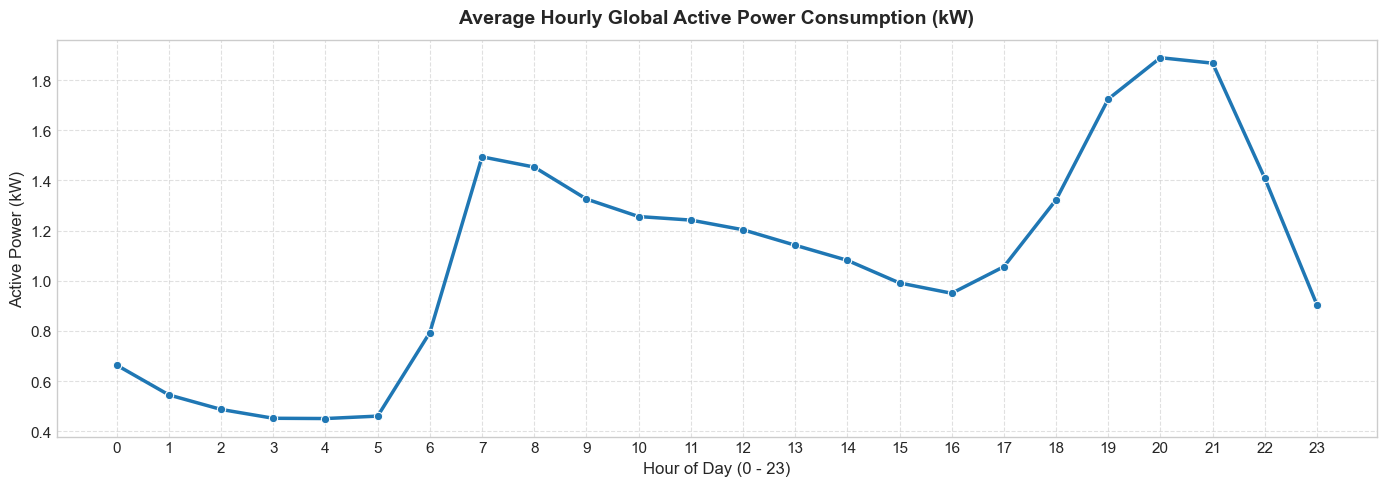

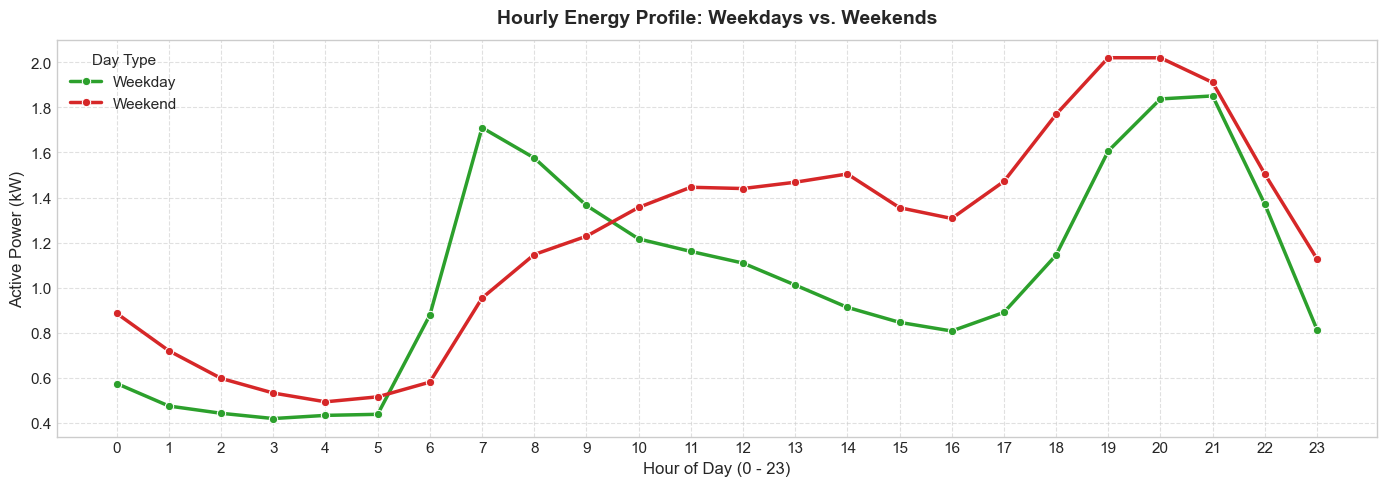

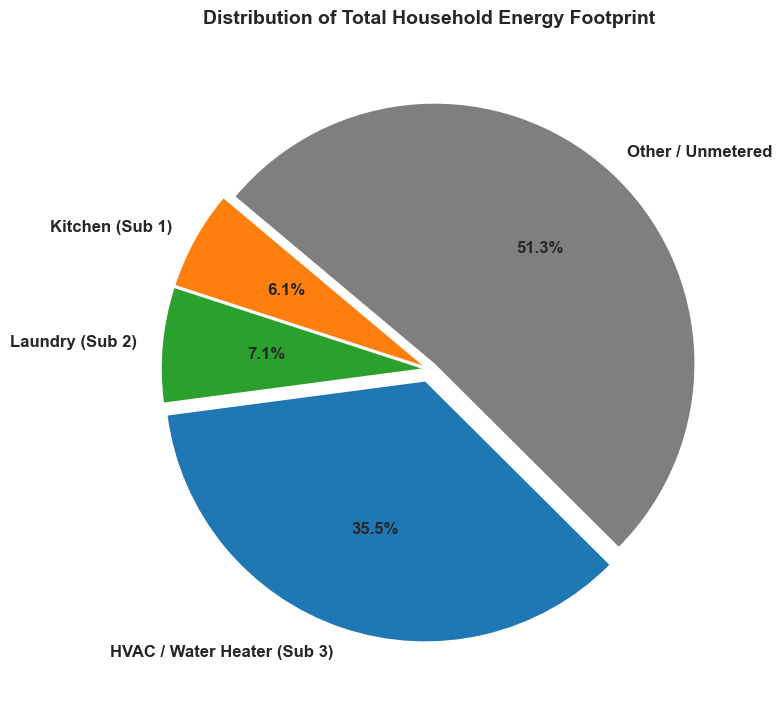

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

# Load hourly processed dataset if not in memory
hourly_df = pd.read_csv('datos_procesados/hourly_power_consumption.csv', parse_dates=['Datetime'], index_col='Datetime')

# Feature Engineering for Time Analysis
hourly_df['Hour'] = hourly_df.index.hour
hourly_df['DayOfWeek'] = hourly_df.index.day_name()
hourly_df['IsWeekend'] = hourly_df.index.dayofweek >= 5
hourly_df['Month'] = hourly_df.index.month_name()
hourly_df['Year'] = hourly_df.index.year

# ==========================================
# 1. HOURLY CONSUMPTION PATTERNS (PEAK HOURS)
# ==========================================
plt.figure(figsize=(14, 5))

# Plot Active Power by Hour of Day
hourly_pattern = hourly_df.groupby('Hour')['Global_active_power'].mean()
sns.lineplot(x=hourly_pattern.index, y=hourly_pattern.values, marker='o', color='#1f77b4', linewidth=2.5)

plt.title('Average Hourly Global Active Power Consumption (kW)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Active Power (kW)', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==========================================
# 2. WEEKDAY VS. WEEKEND LOAD PROFILES
# ==========================================
plt.figure(figsize=(14, 5))

daytype_pattern = hourly_df.groupby(['Hour', 'IsWeekend'])['Global_active_power'].mean().reset_index()
daytype_pattern['DayType'] = daytype_pattern['IsWeekend'].map({True: 'Weekend', False: 'Weekday'})

sns.lineplot(
    data=daytype_pattern, 
    x='Hour', 
    y='Global_active_power', 
    hue='DayType', 
    palette=['#2ca02c', '#d62728'], 
    linewidth=2.5,
    marker='o'
)

plt.title('Hourly Energy Profile: Weekdays vs. Weekends', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Active Power (kW)', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='Day Type', title_fontsize='11', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==========================================
# 3. SUB-METERING BREAKDOWN (APPLIANCE GROUPS)
# ==========================================
# Sub 1 = Kitchen, Sub 2 = Laundry, Sub 3 = HVAC / Water Heater
# Total Active Energy in Watt-hours = (Global_active_power * 1000 / 60)
# Unmetered Energy = Total - (Sub1 + Sub2 + Sub3)

hourly_df['Global_active_energy_Wh'] = hourly_df['Global_active_power'] * 1000
sub1_total = hourly_df['Sub_metering_1'].sum()
sub2_total = hourly_df['Sub_metering_2'].sum()
sub3_total = hourly_df['Sub_metering_3'].sum()

# Compute remaining/unmetered energy
total_measured_sub = sub1_total + sub2_total + sub3_total
total_active_energy = hourly_df['Global_active_energy_Wh'].sum()
unmetered_total = max(0, total_active_energy - total_measured_sub)

submeter_data = pd.Series({
    'Kitchen (Sub 1)': sub1_total,
    'Laundry (Sub 2)': sub2_total,
    'HVAC / Water Heater (Sub 3)': sub3_total,
    'Other / Unmetered': unmetered_total
})

plt.figure(figsize=(8, 8))
colors = ['#ff7f0e', '#2ca02c', '#1f77b4', '#7f7f7f']

plt.pie(
    submeter_data, 
    labels=submeter_data.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors,
    explode=(0.03, 0.03, 0.05, 0.03),
    textprops={'fontsize': 12, 'weight': 'bold'}
)

plt.title('Distribution of Total Household Energy Footprint', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()